# Used-Car Price Prediction Using Machine Learning Regression

# Ramchandra Paudel

## Abstract
This project uses Machine Learning to predict secondhand car prices based on car related data. The data underwent data cleaning, exploratory data analysis, feature engineering and was then fit to a Random Forest regressor. With hyperparameter tuning, the model had an MAE of 7,612.88, a  root mean squared error (RMSE) of 17,994.61 and an R 2 score of 0.2660. This shows that although there are some patterns found by the model, it does not have a high prediction accuracy. There are 278 predictions made from the test data and there is potential to improve the model with higher quality data, better feature engineering and more training data.

## Problem
Predicting used-car prices accurately is challenging because prices depend on various factors, including vehicle age, mileage, condition, and specifications. This project aims to develop a machine learning regression model that predicts used-car prices from available vehicle data.


## Dataset
https://www.kaggle.com/competitions/used-car-price-prediction-challenge/data?utm_source=chatgpt.com

## Step 1 Import Libraries and upload zip file

In [31]:
from pathlib import Path
import zipfile
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_squared_log_error

RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 100)
warnings.filterwarnings("ignore", category=FutureWarning)

# Update ZIP_PATH 
ZIP_PATH = Path("used-car-price-prediction-challenge.zip")
EXTRACT_DIR = Path("used-car-price-prediction-challenge")

## Step 2 Load the three CSV files

In [33]:

def find_csv(filename):
    matches = list(Path(".").rglob(filename))
    if not matches:
        raise FileNotFoundError(
            f"Could not find {filename}. Check that the ZIP is uploaded and extracted."
        )
    return matches[0]

train_path = find_csv("train_data_v2.csv")
test_path = find_csv("test_data_v2.csv")
submission_path = find_csv("sample_submission.csv")

train_data = pd.read_csv(train_path)
test_data = pd.read_csv(test_path)
sample_submission = pd.read_csv(submission_path)

print("Training data shape:", train_data.shape)
print("Test data shape:", test_data.shape)
print("Sample submission shape:", sample_submission.shape)

display(train_data.head())
display(test_data.head())
display(sample_submission.head())

Training data shape: (784, 28)
Test data shape: (278, 27)
Sample submission shape: (278, 2)


,ID,condition,cylinders,drive,engine,est._monthly_pmt,ext_color,feature_count,features_list,fuel,image_count,int_color,make,mileage,model,odometer,paint_color,price,scrape_timestamp,search_price,title,title_status,trans,transmission,trim,type,vin,year
0,1,like new,3 cylinders,4wd,NaN,NaN,NaN,1,QR Code Link to This Post\r\n\r\n\r\n\r\nCACTUS GREY W/ BLACK INTERIOR\r\n\r\nKeyless Entry\r\n1...,gas,4,NaN,NaN,NaN,NaN,60700.0,grey,18500,2026-06-23T20:52:06.693266,NaN,2021 Ford Bronco Sport,clean,NaN,automatic,NaN,SUV,NaN,NaN
1,2,NaN,4 cylinders,rwd,NaN,NaN,NaN,1,QR Code Link to This Post\r \r \r \r Autotrader Private Seller - 2004 Ford Ranger XL -- $Vehicle...,gas,7,NaN,*Ford** Model: *Ranger** Series: *XL** Body Style: Truck* VIN:...,288,*Ranger** Series: *XL** Body Style: Truck* VIN:...,288977.0,NaN,3999,2026-06-23T20:52:10.857962,NaN,2004 Ford Ranger,clean,NaN,other,NaN,truck,1FTYR10DX4PA32355,2004* Make: *Ford** Model: *Ranger** Series: *XL** Body Style: Truck* VIN:...
2,3,NaN,8 cylinders,rwd,NaN,NaN,NaN,1,QR Code Link to This Post\r \r \r \r Autotrader Private Seller - 2004 Ford F-150 Lariat -- $Vehi...,gas,13,NaN,*Ford** Model: *F-150** Series: *Lariat** Body Style: Truck*...,247,*F-150** Series: *Lariat** Body Style: Truck*...,247619.0,white,4999,2026-06-23T20:52:14.989644,NaN,2004 Ford F-150,clean,NaN,other,NaN,truck,1FTPW12534KC63718,2004* Make: *Ford** Model: *F-150** Series: *Lariat** Body Style: Truck*...
3,4,NaN,8 cylinders,rwd,NaN,NaN,NaN,1,QR Code Link to This Post\r \r \r \r Autotrader Private Seller - 2004 Ford Econoline Commercial ...,gas,5,NaN,*Ford**...,117,*Econoline Commercial Cutaway** Series: *Super Duty** Body Style: Coupe* VIN: ...,117000.0,white,4000,2026-06-23T20:52:19.776244,NaN,2004 Ford Econoline Commercial Cutaway,clean,NaN,other,NaN,coupe,1FDSE35L74HA19274,2004* Make: *Ford**...
4,5,NaN,6 cylinders,fwd,NaN,NaN,NaN,1,QR Code Link to This Post\r \r \r \r Autotrader Private Seller - 2001 Buick Regal LS -- $Vehicle...,gas,6,NaN,*Buick** Model: *Regal** Series: *LS** Body Style: Sedan* VIN:...,101,*Regal** Series: *LS** Body Style: Sedan* VIN:...,101000.0,NaN,3500,2026-06-23T20:52:30.715782,NaN,2001 Buick Regal,clean,NaN,other,NaN,sedan,2G4WB55K311332737,2001* Make: *Buick** Model: *Regal** Series: *LS** Body Style: Sedan* VIN:...


,ID,condition,cylinders,drive,engine,est._monthly_pmt,ext_color,feature_count,features_list,fuel,image_count,int_color,make,mileage,model,odometer,paint_color,scrape_timestamp,search_price,title,title_status,trans,transmission,trim,type,vin,year
0,1001,NaN,NaN,NaN,NaN,NaN,NaN,1,QR Code Link to This Post\r\n\r\n\r\n\r\n1965 Ford Mustang Fastback ���� Timeless American muscl...,gas,22,NaN,NaN,NaN,NaN,83489,NaN,2026-06-23T17:50:50.589255,NaN,1965 Ford Mustang Fastback,clean,NaN,automatic,NaN,other,NaN,NaN
1,1002,NaN,6 cylinders,fwd,NaN,NaN,NaN,1,QR Code Link to This Post\r \r \r \r 2002 Chevrolet Monte Carlo SS Pace Car Edition CoupePrice: ...,gas,24,NaN,NaN,NaN,NaN,64131,yellow,2026-06-23T17:51:12.751196,NaN,2002 Chevrolet Monte Carlo SS Pace Car Edition SKU:AA1026 Coupe,clean,NaN,automatic,NaN,coupe,NaN,NaN
2,1003,NaN,NaN,NaN,NaN,NaN,NaN,1,QR Code Link to This Post\r \r \r \r - 350 GM crate motor (L-43 - approx 320 hp with headers and...,gas,18,NaN,NaN,NaN,NaN,61950,NaN,2026-06-23T17:51:25.520115,NaN,1968 Chevelle 300 post,clean,NaN,manual,NaN,NaN,NaN,NaN
3,1004,good,4 cylinders,NaN,NaN,995.0,NaN,1,"QR Code Link to This Post\r\n\r\n\r\n\r\n2023 ISUZU NRR 20ft + LIFTGATE 2500LBS \r\n19,500l...",diesel,24,NaN,NaN,NaN,NaN,95000,white,2026-06-23T17:51:34.427494,NaN,2023 Isuzu NRR 20FT BOX LIFT DSL warranty-finance-ship/delivery 95K mi,clean,NaN,automatic,NaN,truck,JALEXXXXXXX301909,NaN
4,1005,excellent,4 cylinders,NaN,NaN,NaN,NaN,1,QR Code Link to This Post\r\n\r\n\r\n\r\nIf you have any question or want to make an appointment...,gas,18,NaN,NaN,NaN,NaN,96800,black,2026-06-23T17:51:37.982566,NaN,2014 BMW428I COUPE,clean,NaN,automatic,NaN,coupe,NaN,NaN


,ID,price
0,1001,93751
1,1002,92626
2,1003,8702
3,1004,66350
4,1005,23733


## Step 3 Understand the problem and inspect the training data

In [35]:
TARGET = "price"

assert TARGET in train_data.columns, f"Target column '{TARGET}' was not found."
assert TARGET not in test_data.columns, "Test data unexpectedly contains the target price."

print("Training rows and columns:", train_data.shape)
print("\nColumn names:")
print(train_data.columns.tolist())

print("\nData types and non-null counts:")
train_data.info()

print("\nNumerical summary:")
display(train_data.describe(include="number").T)

print("\nAll-column summary:")
display(train_data.describe(include="all").T)

print("\nMissing values (largest first):")
display(train_data.isna().sum().sort_values(ascending=False).to_frame("missing_count"))

print("\nDuplicate training rows:", train_data.duplicated().sum())
print("Missing target values:", train_data[TARGET].isna().sum())
print("Non-positive target prices:", (train_data[TARGET] <= 0).sum())

Training rows and columns: (784, 28)

Column names:
['ID', 'condition', 'cylinders', 'drive', 'engine', 'est._monthly_pmt', 'ext_color', 'feature_count', 'features_list', 'fuel', 'image_count', 'int_color', 'make', 'mileage', 'model', 'odometer', 'paint_color', 'price', 'scrape_timestamp', 'search_price', 'title', 'title_status', 'trans', 'transmission', 'trim', 'type', 'vin', 'year']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 784 entries, 0 to 783
Data columns (total 28 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ID                784 non-null    int64  
 1   condition         500 non-null    object 
 2   cylinders         553 non-null    object 
 3   drive             507 non-null    object 
 4   engine            83 non-null     object 
 5   est._monthly_pmt  2 non-null      object 
 6   ext_color         6 non-null      object 
 7   feature_count     784 non-null    int64  
 8  

,count,mean,std,min,25%,50%,75%,max
ID,784.0,392.500000,226.465597,1.0,196.75,392.5,588.25,784.0
feature_count,784.0,1.000000,0.000000,1.0,1.00,1.0,1.00,1.0
image_count,784.0,15.160714,6.874142,1.0,9.00,16.0,22.00,24.0
odometer,770.0,116738.248052,98062.467505,1.0,72250.00,109817.5,148366.75,1970000.0
price,784.0,23154.093112,206577.479773,0.0,4995.00,9500.0,19123.00,5771710.0
search_price,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN



All-column summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID,784.0,NaN,NaN,NaN,392.5,226.465597,1.0,196.75,392.5,588.25,784.0
condition,500,6,excellent,227,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cylinders,553,8,4 cylinders,215,NaN,NaN,NaN,NaN,NaN,NaN,NaN
drive,507,3,fwd,198,NaN,NaN,NaN,NaN,NaN,NaN,NaN
engine,83,73,V6,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
est._monthly_pmt,2,1,$1,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ext_color,6,6,Gray Int Color: Brown Power Door...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
feature_count,784.0,NaN,NaN,NaN,1.0,0.0,1.0,1.0,1.0,1.0,1.0
features_list,784,767,QR Code Link to This Post For sale at 1775 e43rd st Vernon CA 90058 3237995637 we open monday to...,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fuel,783,5,gas,666,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing values (largest first):


,missing_count
search_price,784
est._monthly_pmt,782
int_color,778
ext_color,778
trans,750
trim,719
model,715
year,711
make,707
engine,701



Duplicate training rows: 0
Missing target values: 0
Non-positive target prices: 1


## Step 4 Exploratory data analysis (EDA)

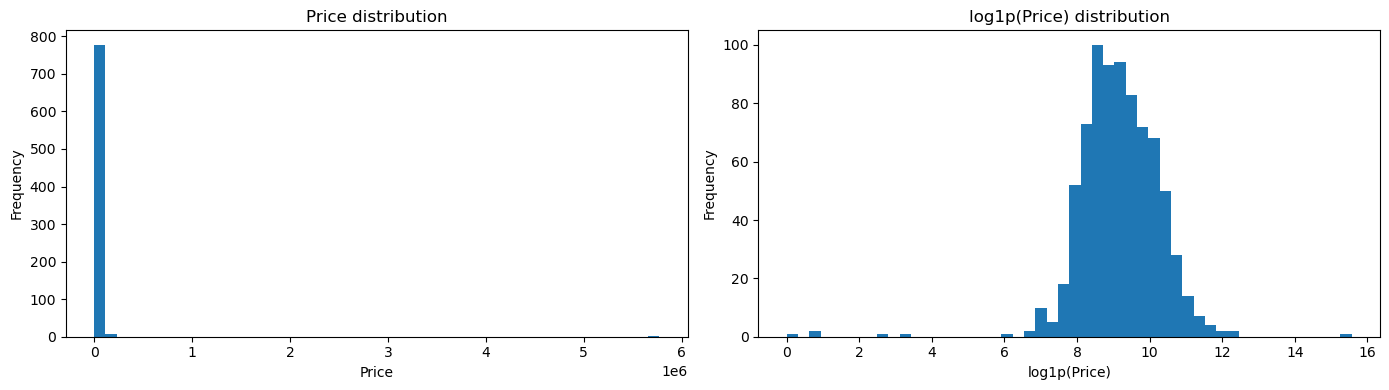

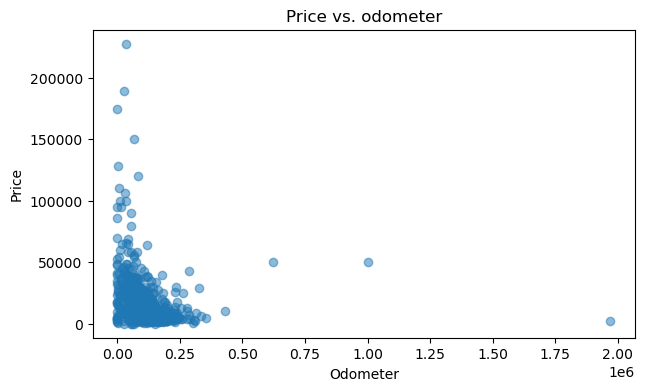

,count,median,mean
make,,,
NaN,707,8500.0,23201.538897
DODGE Model / Trim:...,2,28245.5,28245.500000
ISUZU Model: NPR HD Exterior: White Interior: Gray Mileage: 99,1,25000.0,25000.000000
Lexus Model:ES 300h Trim: Mileage:106,1,26900.0,26900.000000
Lexus Model: ES Trim: ES 300h Sedan 4D Mileage: 130,1,21495.0,21495.000000
Kia Model:Sorento Hybrid Trim:S Mileage:106,1,19900.0,19900.000000
Kia Model:Niro Trim:SX Touring Mileage:116,1,18900.0,18900.000000
International Model: 4300 Odometer: 183418 miles Engine:...,1,24999.0,24999.000000
ISUZU...,1,120000.0,120000.000000


In [38]:
# Target distribution 
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
train_data[TARGET].dropna().plot(kind="hist", bins=50, ax=axes[0], title="Price distribution")
axes[0].set_xlabel("Price")
np.log1p(train_data.loc[train_data[TARGET] >= 0, TARGET]).plot(
    kind="hist", bins=50, ax=axes[1], title="log1p(Price) distribution"
)
axes[1].set_xlabel("log1p(Price)")
plt.tight_layout()
plt.show()

if "odometer" in train_data.columns:
    plt.figure(figsize=(7, 4))
    plt.scatter(train_data["odometer"], train_data[TARGET], alpha=0.5)
    plt.xlabel("Odometer")
    plt.ylabel("Price")
    plt.title("Price vs. odometer")
    plt.show()

if "make" in train_data.columns:
    display(
        train_data.groupby("make", dropna=False)[TARGET]
        .agg(["count", "median", "mean"])
        .sort_values("count", ascending=False)
        .head(15)
    )

##  Step 5. Data Preparation and Feature Engineering
The raw data has missing values and several columns stored as text even when they may contain numbers or dates. The preparation below:
- remove duplicate rows
- keep the price column as the target
- convert the year field to a numeric model year, extracting a four-digit year when the source contains extra text
- converts mileage and est._monthly_pmt to numeric values where possible
- extract date features from scrape_timestamp
- drop identifier or free-text columns likely to be noisly/high-cardinality (ID, vin, title, feature_list, and the original timestamp)
- imputes missing values and one-hot encodes categorical columns inside a scikit-learn pipeline

In [58]:
train = train_data.copy().drop_duplicates()
test = test_data.copy()

TARGET = "price"

# Remove rows with missing or non-positive prices
train = train.loc[
    train[TARGET].notna() & (train[TARGET] > 0)
].copy()


def extract_numeric(series):
    return pd.to_numeric(
        series.astype(str)
        .str.replace(",", "", regex=False)
        .str.extract(r"(-?\d+(?:\.\d+)?)", expand=False),
        errors="coerce"
    )


def prepare_features(frame):
    frame = frame.copy()

    # Convert year to a numeric value
    if "year" in frame.columns:
        frame["year"] = extract_numeric(frame["year"])
        frame.loc[
            ~frame["year"].between(1950, 2035), "year"
        ] = np.nan

    # Convert selected columns to numeric
    for col in [
        "mileage", "est._monthly_pmt",
        "odometer", "feature_count", "image_count"
    ]:
        if col in frame.columns:
            frame[col] = extract_numeric(frame[col])

    # Extract date information
    if "scrape_timestamp" in frame.columns:
        dt = pd.to_datetime(
            frame["scrape_timestamp"],
            errors="coerce",
            utc=True
        )

        frame["scrape_year"] = dt.dt.year
        frame["scrape_month"] = dt.dt.month
        frame["scrape_day"] = dt.dt.day
        frame["scrape_dayofweek"] = dt.dt.dayofweek

        frame = frame.drop(columns=["scrape_timestamp"])

    # Remove target and identifier/free-text columns
    frame = frame.drop(
        columns=[
            "price", "ID", "vin",
            "title", "features_list"
        ],
        errors="ignore"
    )

    # Replace pandas missing values with standard NumPy NaN
    for col in frame.select_dtypes(
        include=["object", "string", "category"]
    ).columns:
        frame[col] = (
            frame[col]
            .astype(object)
            .where(frame[col].notna(), np.nan)
        )

    return frame


X = prepare_features(train)
y = train[TARGET].astype(float)

X_test = prepare_features(test)

# Remove columns that contain no usable values in training data
empty_columns = X.columns[X.isna().all()].tolist()

print("Columns with no training values:", empty_columns)

X = X.drop(columns=empty_columns)

# Keep the same feature columns and order in test data
X_test = X_test.reindex(columns=X.columns)

print("Training features:", X.shape)
print("Test features:", X_test.shape)

display(X.head())


Columns with no training values: ['search_price']
Training features: (783, 25)
Test features: (278, 25)


,condition,cylinders,drive,engine,est._monthly_pmt,ext_color,feature_count,fuel,image_count,int_color,make,mileage,model,odometer,paint_color,title_status,trans,transmission,trim,type,year,scrape_year,scrape_month,scrape_day,scrape_dayofweek
0,like new,3 cylinders,4wd,NaN,NaN,NaN,1,gas,4,NaN,NaN,NaN,NaN,60700.0,grey,clean,NaN,automatic,NaN,SUV,NaN,2026,6,23,1
1,NaN,4 cylinders,rwd,NaN,NaN,NaN,1,gas,7,NaN,*Ford** Model: *Ranger** Series: *XL** Body Style: Truck* VIN:...,288.0,*Ranger** Series: *XL** Body Style: Truck* VIN:...,288977.0,NaN,clean,NaN,other,NaN,truck,2004.0,2026,6,23,1
2,NaN,8 cylinders,rwd,NaN,NaN,NaN,1,gas,13,NaN,*Ford** Model: *F-150** Series: *Lariat** Body Style: Truck*...,247.0,*F-150** Series: *Lariat** Body Style: Truck*...,247619.0,white,clean,NaN,other,NaN,truck,2004.0,2026,6,23,1
3,NaN,8 cylinders,rwd,NaN,NaN,NaN,1,gas,5,NaN,*Ford**...,117.0,*Econoline Commercial Cutaway** Series: *Super Duty** Body Style: Coupe* VIN: ...,117000.0,white,clean,NaN,other,NaN,coupe,2004.0,2026,6,23,1
4,NaN,6 cylinders,fwd,NaN,NaN,NaN,1,gas,6,NaN,*Buick** Model: *Regal** Series: *LS** Body Style: Sedan* VIN:...,101.0,*Regal** Series: *LS** Body Style: Sedan* VIN:...,101000.0,NaN,clean,NaN,other,NaN,sedan,2001.0,2026,6,23,1


## Step 6. Split the dataset into 

In [61]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print("X_train:", X_train.shape)
print("X_valid:", X_valid.shape)
print("y_train:", y_train.shape)
print("y_valid:", y_valid.shape)

X_train: (626, 25)
X_valid: (157, 25)
y_train: (626,)
y_valid: (157,)


## Step 7 Build the preprocessing and model pipeline
Numerical columns are median-imputed
Categorical columns are imputed with the most frequent value and one-hot encoded. 
A RandomForestRegressor is used as a robust baseline. The target is long-transformed with log1p during fitting to reduce the influence of very large prices, predictions are converted back with expm1

OneHotEncoder(sparse_output = ..), replace_output = True with sparse = True

In [65]:
from sklearn.compose import TransformedTargetRegressor

numeric_features = X.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_features = [c for c in X.columns if c not in numeric_features]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=2, sparse_output=True))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

base_model = RandomForestRegressor(
    n_estimators=400,
    min_samples_leaf=2,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

model = TransformedTargetRegressor(
    regressor=Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", base_model)
    ]),
    func=np.log1p,
    inverse_func=np.expm1
)

model

TransformedTargetRegressor(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>,
                           regressor=Pipeline(steps=[('preprocessor',
                                                      ColumnTransformer(transformers=[('num',
                                                                                       Pipeline(steps=[('imputer',
                                                                                                        SimpleImputer(strategy='median'))]),
                                                                                       ['est._monthly_pmt',
                                                                                        'feature_count',
                                                                                        'image_count',
                                                                                        'mileage',
                                                                                        'odometer',
                                                                                        'year',
                                                                                        'scrape_year',
                                                                                        'scrape_month',
                                                                                        'scrape_day',
                                                                                        'scrape_day...
                                                                                                        SimpleImputer(strategy='most_frequent')),
                                                                                                       ('onehot',
                                                                                                        OneHotEncoder(handle_unknown='ignore',
                                                                                                                      min_frequency=2))]),
                                                                                       ['condition',
                                                                                        'cylinders',
                                                                                        'drive',
                                                                                        'engine',
                                                                                        'ext_color',
                                                                                        'fuel',
                                                                                        'int_color',
                                                                                        'make',
                                                                                        'model',
                                                                                        'paint_color',
                                                                                        'title_status',
                                                                                        'trans',
                                                                                        'transmission',
                                                                                        'trim',
                                                                                        'type'])])),
                                                     ('model',
                                                      RandomForestRegressor(min_samples_leaf=2,
                                                                            n_estimators=400,
                                                                            n_jobs=-1,
                                                                            random_state=42))]))

## Step 8. Train the baseline model

In [67]:
model.fit(X_train, y_train)
valid_predictions = np.maximum(model.predict(X_valid), 0)

print("Baseline model trained.")

Baseline model trained.


## Step 9. Evaluate model performance
We report MAE, RMSE, and R^2 on the original price scale. RMSE is also shown because price-prediction tasks often care about relative rrors. It is calculated only on non-negative values

MAE:   7,765.87
RMSE:  18,097.92
R²:    0.2576
RMSLE: 0.8719


,Actual price,Predicted price,Absolute error
211,188999.0,48030.864770,140968.135230
339,105999.0,12901.179140,93097.820860
463,9500.0,80813.395348,71313.395348
618,68995.0,8664.372711,60330.627289
555,63995.0,8815.599375,55179.400625
527,31256.0,63816.393151,32560.393151
458,54500.0,22009.883867,32490.116133
514,44000.0,11843.445277,32156.554723
624,85995.0,54596.922066,31398.077934
447,24.0,28564.006541,28540.006541


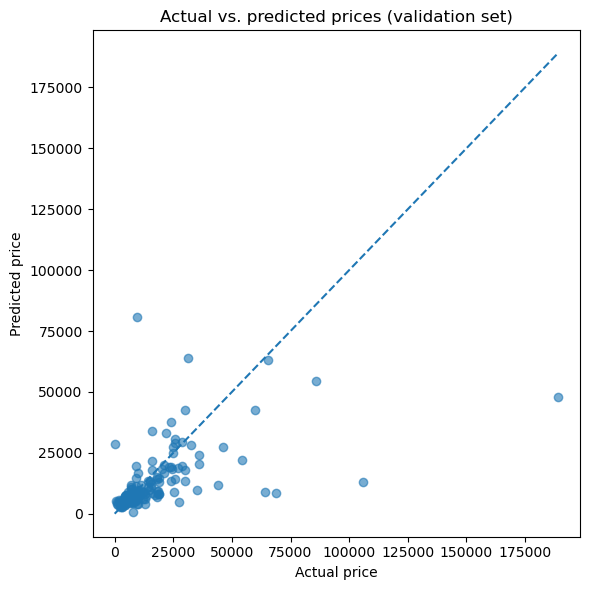

In [69]:
mae = mean_absolute_error(y_valid, valid_predictions)
rmse = np.sqrt(mean_squared_error(y_valid, valid_predictions))
r2 = r2_score(y_valid, valid_predictions)

# RMSLE requires non-negative true and predicted values.
rmsle = np.sqrt(mean_squared_log_error(
    np.maximum(y_valid, 0),
    np.maximum(valid_predictions, 0)
))

print(f"MAE:   {mae:,.2f}")
print(f"RMSE:  {rmse:,.2f}")
print(f"R²:    {r2:.4f}")
print(f"RMSLE: {rmsle:.4f}")

comparison = pd.DataFrame({
    "Actual price": y_valid,
    "Predicted price": valid_predictions,
})
comparison["Absolute error"] = (comparison["Actual price"] - comparison["Predicted price"]).abs()
display(comparison.sort_values("Absolute error", ascending=False).head(15))

plt.figure(figsize=(6, 6))
plt.scatter(y_valid, valid_predictions, alpha=0.6)
max_value = max(float(y_valid.max()), float(valid_predictions.max()))
plt.plot([0, max_value], [0, max_value], linestyle="--")
plt.xlabel("Actual price")
plt.ylabel("Predicted price")
plt.title("Actual vs. predicted prices (validation set)")
plt.tight_layout()
plt.show()

## Step 10. Tune a model hyperparameters
Use the preprocessing pipeline and log-transformed target

In [71]:
# Use a smaller search to keep runtime reasonable for this dataset.
search_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1))
])

search_model = TransformedTargetRegressor(
    regressor=search_pipeline,
    func=np.log1p,
    inverse_func=np.expm1
)

param_distributions = {
    "regressor__model__n_estimators": [200, 400, 600],
    "regressor__model__max_depth": [None, 10, 20, 30],
    "regressor__model__min_samples_split": [2, 5, 10],
    "regressor__model__min_samples_leaf": [1, 2, 4],
    "regressor__model__max_features": [0.5, 0.8, 1.0],
}

# Set n_iter lower (e.g. 5) if you want a faster first run.
random_search = RandomizedSearchCV(
    estimator=search_model,
    param_distributions=param_distributions,
    n_iter=8,
    scoring="neg_mean_absolute_error",
    cv=3,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1,
    error_score="raise"
)

random_search.fit(X_train, y_train)
print("Best CV MAE:", -random_search.best_score_)
print("Best parameters:")
print(random_search.best_params_)

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best CV MAE: 17164.159884721386
Best parameters:
{'regressor__model__n_estimators': 200, 'regressor__model__min_samples_split': 2, 'regressor__model__min_samples_leaf': 2, 'regressor__model__max_features': 0.5, 'regressor__model__max_depth': None}


##  Step 11. Evaluate the tuned model against the baseline

In [73]:
best_model = random_search.best_estimator_
tuned_predictions = np.maximum(best_model.predict(X_valid), 0)

results = pd.DataFrame([
    {
        "Model": "Baseline Random Forest",
        "MAE": mean_absolute_error(y_valid, valid_predictions),
        "RMSE": np.sqrt(mean_squared_error(y_valid, valid_predictions)),
        "R2": r2_score(y_valid, valid_predictions),
    },
    {
        "Model": "Tuned Random Forest",
        "MAE": mean_absolute_error(y_valid, tuned_predictions),
        "RMSE": np.sqrt(mean_squared_error(y_valid, tuned_predictions)),
        "R2": r2_score(y_valid, tuned_predictions),
    }
])
display(results)

,Model,MAE,RMSE,R2
0,Baseline Random Forest,7765.868176,18097.917024,0.257593
1,Tuned Random Forest,7612.877507,17994.614827,0.266044


## Step 12. Fit the selected model on all training data

In [76]:
final_model = random_search.best_estimator_ if "random_search" in globals() else model
final_model.fit(X, y)
print("Final model fitted on all labeled training data.")

Final model fitted on all labeled training data.


## Step 13 Predict prices for test_data

In [79]:
test_predictions = np.maximum(final_model.predict(X_test), 0)

predictions = pd.DataFrame({
    "ID": test_data["ID"] if "ID" in test_data.columns else np.arange(len(test_data)),
    "price": test_predictions
})

display(predictions.head(10))
print("Number of test predictions:", len(predictions))

,ID,price
0,1001,9796.665137
1,1002,25740.948415
2,1003,11116.241442
3,1004,12840.075645
4,1005,12309.243447
5,1006,5783.008967
6,1007,10868.172642
7,1008,5287.941772
8,1009,21608.189739
9,1010,26312.102918


Number of test predictions: 278


## Conclusion
The project involved developing a complete machine learning pipeline to predict second-hand car prices. This included exploring the data, carrying out exploratory data analysis, preprocessing, creating new features, training the model, hyperparameter tuning, evaluation and making predictions. The hyperparameter tuned Random Forest Regressor model performed slightly better than the baseline Random Forest model. The MAE improved from around $7,765.87 to $7,612.88 and the R2 score improved from 0.2576 to 0.2660. However, both the low R2 score and high RMSE suggest the model still has difficulty explaining the variation in car prices. Additionally, the large difference between the MAE and RMSE suggest some cars had large prediction errors. These results could potentially be due to missing car data, a lack of data and outliers. Therefore, the model should be seen as an initial prediction tool rather than an accurate method of predicting car prices. In future work it would be good to validate the outliers, extract useful car information from the listings text, evaluate different regression models and train the model on more representative data. Overall this project shows how machine learning can be applied to predicting second-hand car prices. It also identifies areas to improve in the future.